# 8. Interpretation: which atoms drove the prediction?

**What you will learn:** two ways to get a per-atom explanation out of a
molecular GNN, how to draw them on the structure, and — most importantly —
what each one does and does not entitle you to claim.

This is the notebook that decides whether a chemist will use your model. A
probability of 0.81 is not actionable. "The model is reacting to this
nitroaromatic" is.

Two methods, answering different questions:

| method | question it answers | sign | cost |
|---|---|---|---|
| **attention weights** | where did the model *look*? | non-negative | free |
| **gradient attribution** | what would change the answer? | signed | one backward pass |

Attention is not explanation. This has been argued at length in NLP — Jain, S.;
Wallace, B. C. "Attention is not Explanation." NAACL 2019, DOI:
[10.48550/arXiv.1902.10186](https://doi.org/10.48550/arXiv.1902.10186), and the
reply, Wiegreffe, S.; Pinter, Y. "Attention is not not Explanation." EMNLP
2019, DOI: [10.48550/arXiv.1908.04626](https://doi.org/10.48550/arXiv.1908.04626) —
and the same caution applies to atoms. Treat attention as a hypothesis and
gradients as a test of it.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from mgnn import features as F
from mgnn.data import WORKED_TASKS, load_tox21_graphs
from mgnn.interpret import (
    attention_atom_weights,
    gradient_atom_attribution,
    integrated_gradients_atom_attribution,
)
from mgnn.models import MolecularGNN
from mgnn.splits import scaffold_split
from mgnn.train import evaluate, set_seed, train_model
from mgnn.viz import draw_molecule_with_atom_weights, draw_molecule_with_indices, show

plt.rcParams["figure.dpi"] = 110
torch.set_num_threads(4)
set_seed(0)

## 8.1 Train a model with attention pooling

Attention weights only exist if the architecture has somewhere to put them. We
use attention *readout* (notebook 05) rather than GAT layers here, because the
readout weights are per-atom and molecule-scoped, which is exactly the shape an
explanation needs. Training is short, on the same scaffold split as notebook 07.

In [2]:
ds = load_tox21_graphs(tasks=WORKED_TASKS, verbose=False)
train_idx, valid_idx, test_idx = scaffold_split(ds.smiles, 0.8, 0.1, 0.1)
d_train, d_valid, d_test = ds.subset(train_idx), ds.subset(valid_idx), ds.subset(test_idx)
print(f"{len(d_train)} train / {len(d_valid)} valid / {len(d_test)} test molecules")

set_seed(0)
model = MolecularGNN(n_tasks=2, hidden_dim=64, n_layers=3, layer_kind="gin",
                     pooling="attention", dropout=0.1)
history = train_model(model, d_train.graphs, d_valid.graphs, WORKED_TASKS,
                      epochs=25, batch_size=64, lr=1e-3, weight_decay=1e-5,
                      pos_weight=torch.tensor([5.0, 3.0]), seed=0,
                      verbose=False, early_stopping_patience=10)
test_metrics = evaluate(model, d_test.graphs, WORKED_TASKS)
print(f"best validation ROC-AUC {history.best_valid_roc_auc:.3f} at epoch {history.best_epoch}")
print(f"test ROC-AUC: NR-AR {test_metrics['per_task']['NR-AR']['roc_auc']:.3f}, "
      f"SR-MMP {test_metrics['per_task']['SR-MMP']['roc_auc']:.3f}")
print("\nThis is the model whose explanations we read below. Explaining a model")
print("that does not predict well is a category error -- you would be reading the")
print("structure of its mistakes.")

6258 train / 782 valid / 783 test molecules


best validation ROC-AUC 0.812 at epoch 22
test ROC-AUC: NR-AR 0.694, SR-MMP 0.733

This is the model whose explanations we read below. Explaining a model
that does not predict well is a category error -- you would be reading the
structure of its mistakes.


## 8.2 One molecule, three views

We take a test-set molecule the model scores as likely SR-MMP active and look
at it three ways: readout attention, gradient attribution, and integrated
gradients.

Colour convention throughout this repository: **red pushes the prediction up,
blue pushes it down**, intensity is magnitude. Attention is non-negative so it
is drawn on a one-sided red scale.

473 test molecules measured in SR-MMP; 92 of them are active

chosen molecule: CN(C)c1ccc(C(=C2C=CC(=[N+](C)C)C=C2)c2ccccc2)cc1.CN(C)c1ccc(C(=C2C=CC(=[N+](C)C)C=C2)c2ccccc2)cc1
  measured label: ACTIVE, model probability: 0.830, atoms: 50


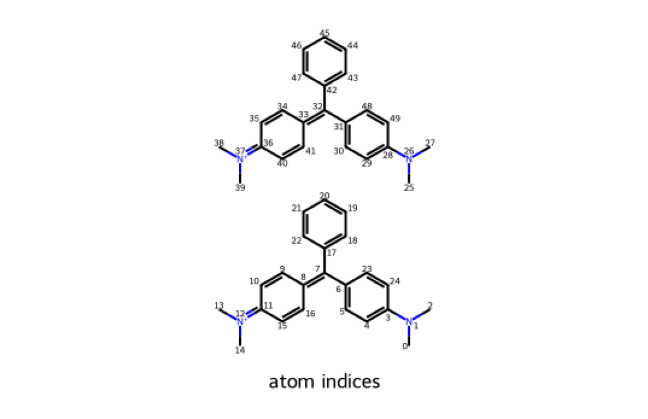

In [3]:
SR_MMP = WORKED_TASKS.index("SR-MMP")

with torch.no_grad():
    scored = []
    for g in d_test.graphs:
        if g.y_mask is not None and bool(g.y_mask[SR_MMP]):
            batch = torch.zeros(g.num_nodes, dtype=torch.long)
            logit = model(g.x, g.edge_index, batch, n_graphs=1)[0, SR_MMP]
            scored.append((float(torch.sigmoid(logit)), float(g.y[SR_MMP]), g))

actives = sorted([s for s in scored if s[1] == 1.0], key=lambda t: -t[0])
print(f"{len(scored)} test molecules measured in SR-MMP; "
      f"{len(actives)} of them are active")

prob, label, graph = actives[1]
smiles = graph.smiles
labels = [f"{s}{i}" for i, s in enumerate(graph.atom_symbols())]
print(f"\nchosen molecule: {smiles}")
print(f"  measured label: {'ACTIVE' if label else 'inactive'}, "
      f"model probability: {prob:.3f}, atoms: {graph.num_nodes}")
show(draw_molecule_with_indices(smiles, size=(520, 330), legend="atom indices"))
plt.show()

In [4]:
att = attention_atom_weights(model, graph)
grad = gradient_atom_attribution(model, graph, task_index=SR_MMP)
ig = integrated_gradients_atom_attribution(model, graph, task_index=SR_MMP, steps=32)

table = pd.DataFrame({
    "atom": labels,
    "attention": att,
    "gradient x input": grad,
    "integrated gradients": ig,
}).set_index("atom")
display(table.style.format("{:+.4f}")
        .background_gradient(cmap="Reds", subset=["attention"])
        .background_gradient(cmap="coolwarm", subset=["gradient x input", "integrated gradients"]))

print("attention sums to:", f"{att.sum():.6f}", "(a distribution over atoms)")
print("gradient attribution sums to:", f"{grad.sum():+.4f}",
      "(signed; no reason to sum to anything in particular)")

,attention,gradient x input,integrated gradients
atom,,,
C0,+0.0048,+0.0180,+0.0202
N1,+0.0057,+0.0270,+0.1078
C2,+0.0048,+0.0180,+0.0202
C3,+0.0122,-0.0068,+0.0428
C4,+0.0066,+0.0218,+0.0753
C5,+0.0058,-0.0045,+0.0478
C6,+0.0054,+0.0352,+0.0878
C7,+0.0193,+0.0555,+0.1434
C8,+0.0169,+0.0351,+0.2709


attention sums to: 1.000000 (a distribution over atoms)
gradient attribution sums to: +0.8956 (signed; no reason to sum to anything in particular)


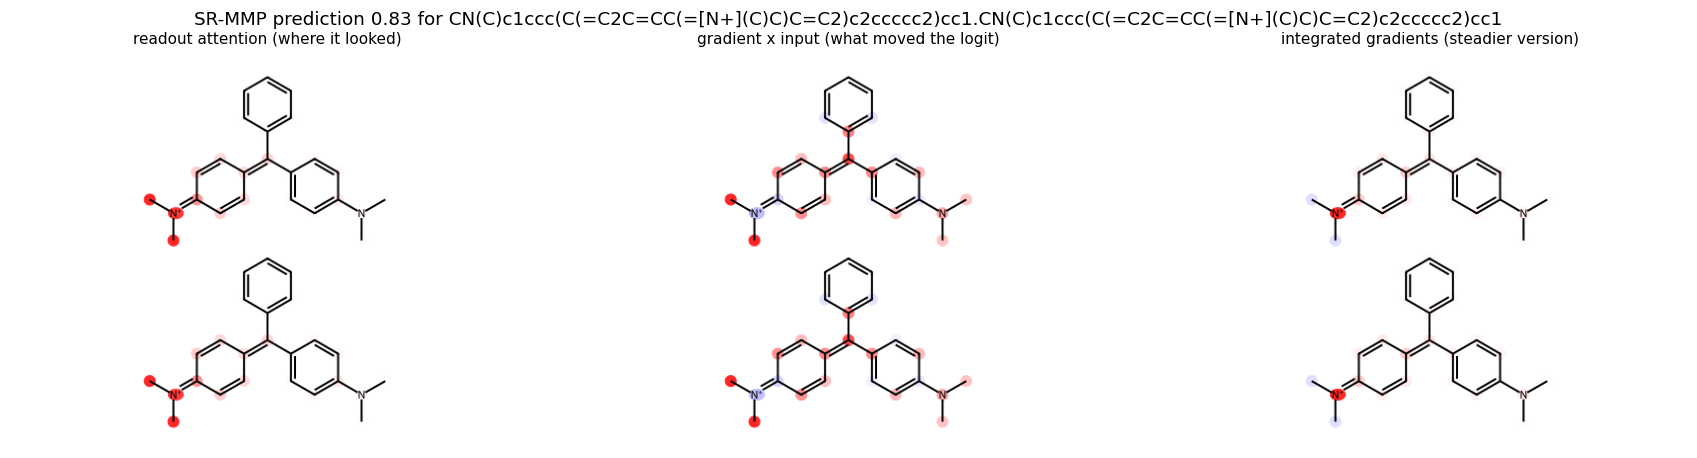

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, (title, w, diverging) in zip(axes, [
    ("readout attention (where it looked)", att, False),
    ("gradient x input (what moved the logit)", grad, True),
    ("integrated gradients (steadier version)", ig, True),
]):
    img = draw_molecule_with_atom_weights(smiles, w, diverging=diverging, size=(520, 400))
    ax.imshow(img); ax.set_axis_off(); ax.set_title(title, fontsize=10)
fig.suptitle(f"SR-MMP prediction {prob:.2f} for {smiles}", y=0.98)
fig.tight_layout()
plt.show()

### How to read these three panels

* **Attention** spreads over whichever atoms the readout found salient. Because
  it is a softmax over atoms, a small molecule's atoms all get substantial
  weight whether or not any of them matter — it is a *relative* quantity inside
  one molecule and cannot be compared across molecules of different size.
* **Gradient × input** is signed, so it separates atoms pushing towards
  "active" (red) from atoms pushing away (blue). It is a local linearisation:
  valid for a small perturbation, and noisy where the model is nonlinear.
* **Integrated gradients** averages gradients along a path from an all-zero
  baseline, which removes much of that noise at 32× the cost. The baseline is a
  choice, and here a "molecule with no features" is a fairly artificial one —
  worth stating when you publish a figure like this.

Where the three agree, you have something worth showing a chemist. Where they
disagree, you have learned that the explanation is unstable, which is itself
the useful result.

In [6]:
corr = table.corr(method="spearman")
print("Spearman correlation between the three attributions on this molecule:")
display(corr.style.format("{:.3f}"))

Spearman correlation between the three attributions on this molecule:


,attention,gradient x input,integrated gradients
attention,1.000,0.325,0.423
gradient x input,0.325,1.000,0.002
integrated gradients,0.423,0.002,1.000


## 8.3 Several molecules at once

One molecule is an anecdote. Here are the model's top-scoring test actives,
each with its gradient attribution. Patterns that recur across molecules are
far more credible than anything visible in a single structure.

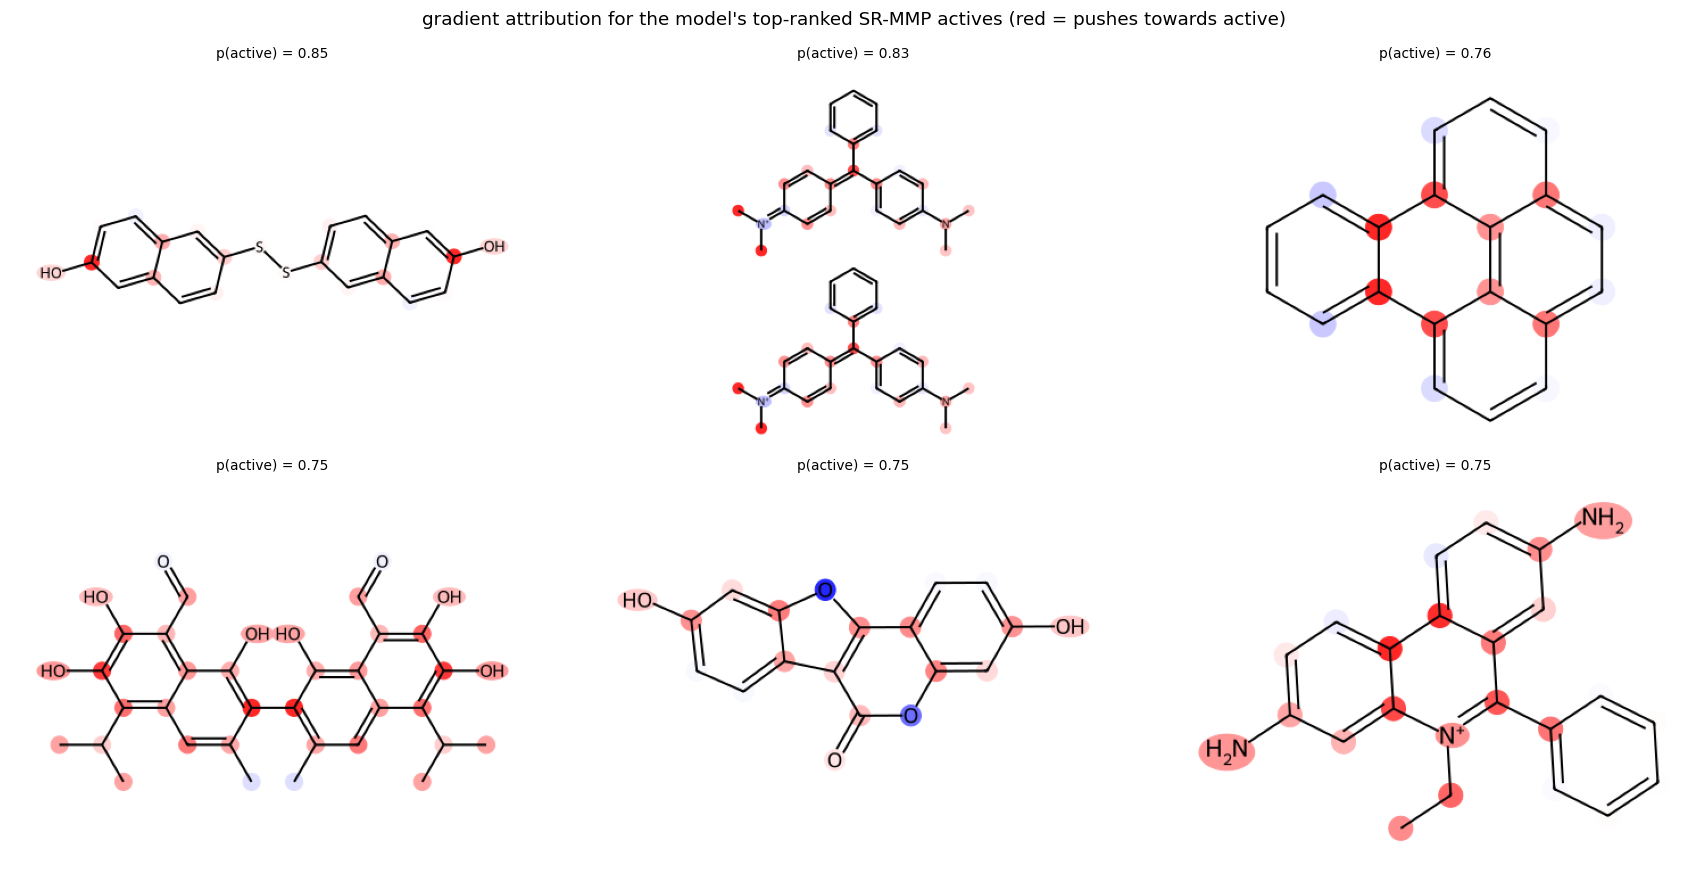

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, (p, lab, g) in zip(axes.ravel(), actives[:6]):
    w = gradient_atom_attribution(model, g, task_index=SR_MMP)
    img = draw_molecule_with_atom_weights(g.smiles, w, diverging=True, size=(460, 340))
    ax.imshow(img); ax.set_axis_off()
    ax.set_title(f"p(active) = {p:.2f}", fontsize=9)
fig.suptitle("gradient attribution for the model's top-ranked SR-MMP actives "
             "(red = pushes towards active)", y=0.99)
fig.tight_layout()
plt.show()

## 8.4 A sanity check that most interpretability figures skip

If an attribution means anything, **removing the atoms it points at should
change the prediction more than removing random atoms.** We cannot delete atoms
from a molecule and keep it chemically sensible, but we can zero out their
feature vectors, which is the graph equivalent of masking.

This is a crude faithfulness test in the spirit of the "deletion" metrics used
in the vision literature, and it is cheap enough that there is no excuse for
not running it.

In [8]:
def masked_probability(g, atoms_to_mask, task_index):
    x = g.x.clone()
    x[list(atoms_to_mask)] = 0.0
    with torch.no_grad():
        batch = torch.zeros(g.num_nodes, dtype=torch.long)
        return float(torch.sigmoid(model(x, g.edge_index, batch, n_graphs=1)[0, task_index]))

rng = np.random.default_rng(0)
rows = []
for p, lab, g in actives[:12]:
    k = max(1, g.num_nodes // 5)                  # mask the top 20% of atoms
    w = gradient_atom_attribution(model, g, task_index=SR_MMP)
    top = np.argsort(-w)[:k]
    drop_top = p - masked_probability(g, top, SR_MMP)
    drops_random = [p - masked_probability(g, rng.choice(g.num_nodes, k, replace=False), SR_MMP)
                    for _ in range(5)]
    rows.append({"smiles": g.smiles[:40], "atoms": g.num_nodes, "masked": k,
                 "p(active)": p, "drop, top-attributed": drop_top,
                 "drop, random (mean of 5)": float(np.mean(drops_random))})

faith = pd.DataFrame(rows)
display(faith.style.format({"p(active)": "{:.3f}", "drop, top-attributed": "{:+.3f}",
                            "drop, random (mean of 5)": "{:+.3f}"}))
print(f"\nmean drop when masking top-attributed atoms: "
      f"{faith['drop, top-attributed'].mean():+.3f}")
print(f"mean drop when masking random atoms:          "
      f"{faith['drop, random (mean of 5)'].mean():+.3f}")
print(f"attribution beats random on {int((faith['drop, top-attributed'] > faith['drop, random (mean of 5)']).sum())} "
      f"of {len(faith)} molecules")

,smiles,atoms,masked,p(active),"drop, top-attributed","drop, random (mean of 5)"
0,Oc1ccc2cc(SSc3ccc4cc(O)ccc4c3)ccc2c1,24,4,0.850,+0.669,+0.283
1,CN(C)c1ccc(C(=C2C=CC(=[N+](C)C)C=C2)c2cc,50,10,0.830,+0.001,+0.071
2,c1ccc2c(c1)c1cccc3ccc4cccc2c4c31,20,4,0.757,+0.402,+0.116
3,Cc1cc2c(C(C)C)c(O)c(O)c(C=O)c2c(O)c1-c1c,38,7,0.751,+0.584,+0.284
4,O=c1oc2cc(O)ccc2c2oc3cc(O)ccc3c12,20,4,0.750,+0.566,+0.244
5,CC[n+]1c(-c2ccccc2)c2cc(N)ccc2c2ccc(N)cc,24,4,0.749,+0.245,+0.136
6,O=c1c(-c2ccccc2)c1-c1ccccc1,16,3,0.732,+0.298,+0.149
7,Oc1ccc(C2(c3ccc(O)cc3)CC3CC2C2CCCC32)cc1,24,4,0.724,+0.467,+0.313
8,CCCN(CC1CC1)c1c([N+](=O)[O-])cc(C(F)(F)F,24,4,0.714,+0.176,+0.076
9,c1ccc2c(c1)Oc1ccccc1S2,14,2,0.703,+0.462,+0.133



mean drop when masking top-attributed atoms: +0.388
mean drop when masking random atoms:          +0.197
attribution beats random on 11 of 12 molecules


A larger drop for the attributed atoms than for random atoms is the minimum
bar an explanation should clear. If your attribution fails this test, do not
publish the pretty picture.

## 8.5 Where the model looks on a molecule it gets wrong

The most useful explanations are usually of the *mistakes*. Here is the
highest-confidence false positive in the test set: a compound the model calls
active that the assay called inactive.

c1ccc(NNc2ccccc2)cc1
  measured inactive, model says 0.809


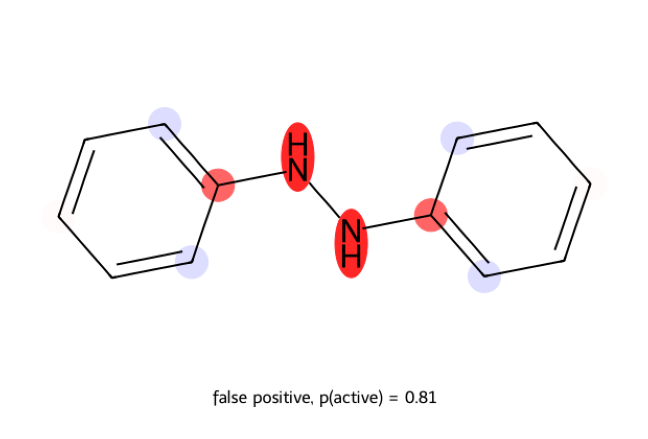

Figures like this are what a project review should spend its time on:
they show whether the model is reacting to chemistry or to an artefact of
the training set.


In [9]:
false_positives = sorted([s for s in scored if s[1] == 0.0], key=lambda t: -t[0])
p_fp, _lab_fp, g_fp = false_positives[0]
print(f"{g_fp.smiles}\n  measured inactive, model says {p_fp:.3f}")

w_fp = gradient_atom_attribution(model, g_fp, task_index=SR_MMP)
show(draw_molecule_with_atom_weights(
    g_fp.smiles, w_fp, diverging=True, size=(600, 400),
    legend=f"false positive, p(active) = {p_fp:.2f}"))
plt.show()
print("Figures like this are what a project review should spend its time on:")
print("they show whether the model is reacting to chemistry or to an artefact of")
print("the training set.")

## 8.6 The README figure

The hero image at the top of this repository is generated here, so it is
reproducible rather than decorative.

wrote /workspace/gnn-for-molecules/assets/attention_molecule.png (42 kB)


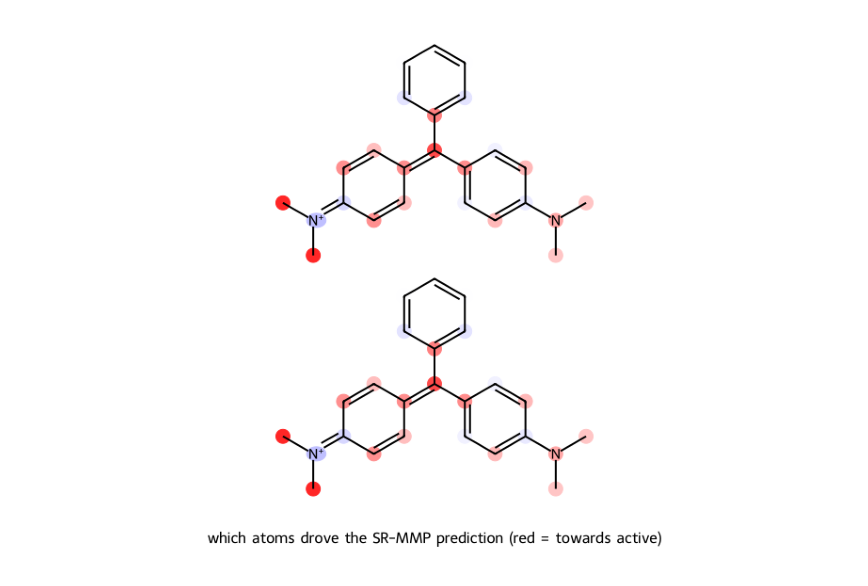

In [10]:
assets = os.path.join("..", "assets")
os.makedirs(assets, exist_ok=True)
hero = draw_molecule_with_atom_weights(
    smiles, grad, diverging=True, size=(900, 600), annotate_values=False,
    legend="which atoms drove the SR-MMP prediction (red = towards active)")
hero_path = os.path.join(assets, "attention_molecule.png")
hero.save(hero_path)
print("wrote", os.path.abspath(hero_path), f"({os.path.getsize(hero_path) / 1024:.0f} kB)")
show(hero, figsize=(8, 5.5))
plt.show()

## What to take away

* Attention tells you where the model looked; gradients tell you what moved
  the answer. Show both, and say which is which.
* Attention is molecule-scoped and non-negative — never compare it across
  molecules of different size.
* Run a masking/faithfulness check before you believe any attribution figure.
* Explain the model's errors, not just its successes.

**Next:** notebook 09 steps back thirty years, to the 1995 architecture that
mapped a molecular graph straight into a neural network.